---
title: "Sektorale Energieallokation – Transition 2040"
lang: de
format:
  html:
    code-fold: true
    code-summary: "Berechnung anzeigen"
execute:
  echo: true
  warning: false
jupyter: python3
---

# Quantitative sektorale Allokation {#sec-allokation-notebook}

Stand: 23. Oktober 2026. Dieser Anhang berechnet die Top-down-Grundlage der PEQ-Kalibrierung: den nationalen elektrischen Gebäudesektorsaldo einschließlich MIV und ein einmalig zugeteiltes elektrisches MIV-Budget. Alle fachlichen Rechnungen stehen in diesen Zellen. Die Gebäudetypologien und ihre Flächen werden erst nach Vorliegen der aktualisierten Excel bearbeitet.

**Quellen:** UBA REP-0880, Tabelle 15, S. 60 (Strombedarf) und Tabelle 16, S. 63 (Erzeugung/Nettohandel), Ausgabe ©2024, Titelblatt 2023 [@uba2023transition]. Die Zuordnungslogik folgt der in @sec-allokation beschriebenen Weiterentwicklung der historischen Methode [@schneider2020lokal; @schneider2023context]. Die nachfolgenden Parameter sind ausdrücklich eigene vorläufige Rechenannahmen, keine vom UBA veröffentlichten Verkehrs- oder PV-Anteile.

## 1. Bilanzgrenze und Einheiten

Alle Flüsse sind jährliche **elektrische Endenergie in PJ/a**; 1 PJ = 1/3,6 TWh. Positive Salden bedeuten Deckung minus Bedarf. Gebäude umfassen hier die UBA-Betriebsposition sowie den zugeordneten MIV. Nicht-elektrische Wärme, Brennstoffe, graue Energie und Primärenergie werden nicht mit Strom addiert. Ein virtuelles MIV-Budget ist eine Zuordnung vorhandener Erzeugung, keine zusätzliche Energiequelle.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'_quarto.yml').exists())
DATA = ROOT/'Daten/sektorenmodell'
OUT = ROOT/'Berechnungen/sektorenmodell/outputs/allokation'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':130, 'font.size':10, 'axes.spines.top':False, 'axes.spines.right':False})
tables={name:pd.read_csv(DATA/name) for name in ['stromerzeugung_2040.csv','strombedarf_2040.csv']}
selected={name:df.loc[df.scenario.eq('transition_2040')].copy() for name,df in tables.items()}
for name,df in selected.items():
    assert df.metric.is_unique and df.value_pj.notna().all()
    assert df.year.eq(2040).all() and df.source_id.eq('TRANSITION').all()
    display(df[['metric','value_pj','energy_basis','source_location']])
g=selected['stromerzeugung_2040.csv'].set_index('metric').value_pj.to_dict()
d=selected['strombedarf_2040.csv'].set_index('metric').value_pj.to_dict()
provenance={name:hashlib.sha256((DATA/name).read_bytes()).hexdigest() for name in tables}


,metric,value_pj,energy_basis,source_location
18,fossil,1,electricity_generation_or_net_import,"Tabelle 16, S. 63"
19,hydro,173,electricity_generation_or_net_import,"Tabelle 16, S. 63"
20,biomass,21,electricity_generation_or_net_import,"Tabelle 16, S. 63"
21,geothermal,4,electricity_generation_or_net_import,"Tabelle 16, S. 63"
22,pv,149,electricity_generation_or_net_import,"Tabelle 16, S. 63"
23,wind,105,electricity_generation_or_net_import,"Tabelle 16, S. 63"
24,hydrogen_electricity,4,electricity_generation_or_net_import,"Tabelle 16, S. 63"
25,generation_published_total,457,electricity_generation_or_net_import,"Tabelle 16, S. 63"
26,net_imports,-7,electricity_generation_or_net_import,"Tabelle 16, S. 63"


,metric,value_pj,energy_basis,source_location
16,verkehr,90,electricity_demand,"Tabelle 15, S. 60"
17,gebaeude,108,electricity_demand,"Tabelle 15, S. 60"
18,landwirtschaft,4,electricity_demand,"Tabelle 15, S. 60"
19,industrie,140,electricity_demand,"Tabelle 15, S. 60"
20,verbrauch_sektor_energie,34,electricity_demand,"Tabelle 15, S. 60"
21,transportverluste,19,electricity_demand,"Tabelle 15, S. 60"
22,umwandlungseinsatz,57,electricity_demand,"Tabelle 15, S. 60"
23,electricity_demand_published_total,450,electricity_demand,"Tabelle 15, S. 60"


## 2. Quellbilanz vor Allokation

\(R_{Quelle}=G+I-D\). Nettoimporte \(I<0\) sind Exporte. Die gedruckte Gesamtsumme des Bedarfs wird neben der Summe der Komponenten erhalten. Die Zuordnung arbeitet mit den Komponenten, ohne ihren Unterschied zu verteilen.


In [2]:
generation_keys=['hydro','wind','biomass','geothermal','hydrogen_electricity','pv','fossil']
demand_keys=['verkehr','gebaeude','industrie','landwirtschaft','verbrauch_sektor_energie','transportverluste','umwandlungseinsatz']
source_generation=sum(g[k] for k in generation_keys)
source_demand=sum(d[k] for k in demand_keys)
source_residual=source_generation+g['net_imports']-source_demand
assert source_generation==457 and source_demand==452 and source_residual==-2
display(pd.DataFrame({'Position':['Erzeugung','Nettoimporte','Bedarf publiziert','Bedarf Komponenten','Rest Komponenten'],
                      'PJ_el/a':[source_generation,g['net_imports'],d['electricity_demand_published_total'],source_demand,source_residual]}))


,Position,PJ_el/a
0,Erzeugung,457
1,Nettoimporte,-7
2,Bedarf publiziert,450
3,Bedarf Komponenten,452
4,Rest Komponenten,-2


## 3. Sichtbare Stellschrauben und Referenzannahmen

\(f\) ist der Anteil der PV außerhalb von Gebäuden; der Gebäudebeitrag beträgt \((1-f)G_{PV}\). Andere PV bleibt als **separat noch nicht zugeteilter Pool** erhalten, nicht als implizite MIV-Gutschrift. \(m,o,r\) sind Anteile des **elektrischen Verkehrsenergiebedarfs** für MIV, ÖPNV und übrigen Verkehr; \(m+o+r=1\). Sie sind keine Wege- oder Personenkilometeranteile.

Das Rechenbeispiel verwendet 0 % andere PV und 80/20/0 % MIV/ÖPNV/übrigen Verkehr. Dies sind austauschbare Demonstrationswerte, keine Empfehlung oder empirische Festlegung. Die dritte Verkehrskategorie bleibt als Parameter erhalten.

Wasser, Wind und Biomasse werden im Rechenfall dem nicht-PV-Pool zugeordnet; die normierte Position „Geothermie/sonstige“ wird vorläufig vollständig angerechnet und muss bei veränderter Abgrenzung angepasst werden. Wasserstoff-Rückverstromung wird zunächst **nicht** als budgetfähig angerechnet, weil ihr Herkunftsnachweis hier nicht vorliegt. Die alternative volle Anrechnung wird separat ausgewiesen. Fossile Erzeugung bleibt außerhalb des erneuerbaren Budgets.

Industrie, Landwirtschaft, Energiebranchenbedarf, Umwandlung, Transportverluste und Nettoexport werden einmalig vorrangig aus dem zentralen Pool abgezogen. ÖPNV und übriger Verkehr folgen ebenfalls diesem Pool. Insbesondere bleibt der Elektrolyse-Strombedarf erhalten, auch wenn Rückverstromung angerechnet wird. Die Priorität ist eine Modellentscheidung; die UBA-Tabellen beschreiben keine solche Allokation.


In [3]:
parameters={
    'other_pv_share':0.0,
    'miv_share':0.8,
    'public_transport_share':0.2,
    'other_transport_share':0.0,
    'eligible_nonpv_share':{'hydro':1.0,'wind':1.0,'biomass':1.0,'geothermal':1.0,'hydrogen_electricity':0.0},
    'source':'Vorläufiges redaktionelles Rechenbeispiel; Verkehrs- und PV-Anteile nicht empirisch festgelegt',
    'pe_factor_electricity':None,
    'pe_factor_year':None,
    'pe_factor_source':None,
}
display(pd.DataFrame([{'Parameter':k,'Wert':str(v)} for k,v in parameters.items()]))


,Parameter,Wert
0,other_pv_share,0.0
1,miv_share,0.8
2,public_transport_share,0.2
3,other_transport_share,0.0
4,eligible_nonpv_share,"{'hydro': 1.0, 'wind': 1.0, 'biomass': 1.0, 'g..."
5,source,Vorläufiges redaktionelles Rechenbeispiel; Ver...
6,pe_factor_electricity,None
7,pe_factor_year,None
8,pe_factor_source,None


## 4. Zentraler Pool und MIV-Budget

\[
C=\sum_{i\ne PV} a_iG_i,\quad
F=D_{Industrie}+D_{Landwirtschaft}+D_{Energie}+D_{Umwandlung}+D_{Verluste}+Export,
\]
\[
R=C-F-(o+r)D_{Verkehr},\qquad
M=\min\{\max(R,0),mD_{Verkehr}\}.
\]

\(a_i\) bezeichnet die gesetzte Budgetfähigkeit. Der rohe Rest \(R\) bleibt sichtbar: \(R<0\) bedeutet einen zentralen Deckungsfehlbetrag, nicht eine negative Gutschrift. Der zugeteilte Betrag \(M\) ist auf den MIV-Bedarf begrenzt; ein darüber hinausgehender Rest bleibt unverteilt. Positive Nettoimporte würden gesondert unzugeordnet bleiben; es gibt keine automatische Herkunftsanrechnung.

## 5. Gebäudesektorsaldo und vollständige Zuordnungsprüfung

\[
B_{Geb}=(1-f)G_{PV}+M-D_{Geb}-mD_{Verkehr}.
\]

Der betriebliche Saldo ohne MIV wird separat gezeigt. Für den Bilanzschluss werden alle ausgeschlossenen oder noch nicht zugeordneten Erzeugungsmengen und der zentrale Rest nach MIV-Zuteilung mitgeführt:
\[
B_{Geb}+R_{zentral,nachMIV}+G_{PV,sonstige}+G_{nicht\ budgetfähig}+I_+=R_{Quelle}.
\]

Diese Identität verhindert, dass ein Pool verschwindet oder doppelt gutgeschrieben wird. Ein negativer zentraler Rest macht den Rechenfall als unvollständig gedeckt kenntlich, auch wenn der Gebäudesaldo allein günstig aussieht.


In [4]:
# Fachliche Modellfunktion bewusst in der Notebook-Zelle, nicht in einem externen Modul.
def allocate(p):
    for key in ['other_pv_share','miv_share','public_transport_share','other_transport_share']:
        assert np.isfinite(p[key]) and 0<=p[key]<=1, key
    assert np.isclose(sum(p[k] for k in ['miv_share','public_transport_share','other_transport_share']),1)
    assert set(p['eligible_nonpv_share'])=={'hydro','wind','biomass','geothermal','hydrogen_electricity'}
    assert all(np.isfinite(v) and 0<=v<=1 for v in p['eligible_nonpv_share'].values())
    central=sum(g[k]*share for k,share in p['eligible_nonpv_share'].items())
    export=max(-g['net_imports'],0)
    fixed=sum(d[k] for k in ['industrie','landwirtschaft','verbrauch_sektor_energie','umwandlungseinsatz','transportverluste'])+export
    miv=d['verkehr']*p['miv_share']
    public=d['verkehr']*p['public_transport_share']
    other=d['verkehr']*p['other_transport_share']
    raw=central-fixed-public-other
    budget=min(max(raw,0),miv)
    pv_building=g['pv']*(1-p['other_pv_share'])
    pv_other=g['pv']*p['other_pv_share']
    unassigned_nonpv=source_generation-g['pv']-central
    building_operation=pv_building-d['gebaeude']
    building=building_operation+budget-miv
    central_after=raw-budget
    closure=building+central_after+pv_other+unassigned_nonpv+max(g['net_imports'],0)
    assert np.isclose(closure,source_residual), 'Zuordnungsbilanz verletzt'
    assert 0<=budget<=miv
    return dict(central_pj=central,fixed_priority_pj=fixed,public_transport_pj=public,other_transport_pj=other,
                miv_demand_pj=miv,raw_miv_balance_pj=raw,miv_budget_pj=budget,
                central_after_miv_pj=central_after,unassigned_nonpv_pj=unassigned_nonpv,
                building_pv_pj=pv_building,other_pv_pj=pv_other,building_operation_pj=building_operation,
                building_target_pj=building,source_residual_pj=source_residual,allocation_residual_pj=closure,
                priority_covered=raw>=-1e-9)
result=allocate(parameters)
result_table=pd.DataFrame([{'Position':k,'PJ_el/a':v,'TWh_el/a':v/3.6} for k,v in result.items() if k!='priority_covered'])
display(result_table.round(4))


,Position,PJ_el/a,TWh_el/a
0,central_pj,303.0,84.1667
1,fixed_priority_pj,261.0,72.5000
2,public_transport_pj,18.0,5.0000
3,other_transport_pj,0.0,0.0000
4,miv_demand_pj,72.0,20.0000
5,raw_miv_balance_pj,24.0,6.6667
6,miv_budget_pj,24.0,6.6667
7,central_after_miv_pj,0.0,0.0000
8,unassigned_nonpv_pj,5.0,1.3889
9,building_pv_pj,149.0,41.3889


## 6. Interpretation und wenige transparente Varianten

Im Beispiel werden 303 PJ als zentral budgetfähig behandelt und 261 PJ für die festen vorrangigen Positionen verwendet. Bei 72 PJ MIV und 18 PJ ÖPNV verbleiben **24 PJ = 6,667 TWh elektrisches MIV-Budget**. Der Gebäudebetrieb allein hat mit 149 PJ Gebäude-PV und 108 PJ Bedarf einen Saldo von +41 PJ. Nach MIV-Bedarf und einmaliger MIV-Deckung beträgt der erweiterte Gebäudesektor-Zielsaldo **−7 PJ/a**.

Die 4 PJ nicht angerechnete Rückverstromung und 1 PJ fossile Erzeugung verschwinden nicht: Zusammen mit −7 PJ Gebäudesaldo ergeben sie den Quellrest −2 PJ. Eine volle, ausdrücklich bedingte Anrechnung der Rückverstromung erhöht das MIV-Budget auf 28 PJ und den Gebäudesaldo auf −3 PJ.

Solange der zentrale Pool die prioritären Bedarfe deckt und kein über den MIV-Bedarf hinausgehender Überschuss entsteht, gilt für den obigen Technologiefall:
\[
M=90m-48+4h,\qquad B_{Geb}=-7+4h-149f,
\]
mit \(h\) als angerechnetem Anteil der 4 PJ Rückverstromung. Die Verkehrsaufteilung verändert dann das MIV-Budget, nicht den verbleibenden Gebäudesaldo: Die zugeordnete Deckung und der zugeordnete Bedarf ändern sich gleichzeitig. Unterhalb der Deckungsschwelle \(m\ge(48-4h)/90\) gilt diese vereinfachte Formel nicht. Die folgenden wenigen Varianten sind keine Optimierung und bestimmen keinen optimalen PV- oder Verkehrsanteil.


,Variante,Andere PV [%],MIV [%],H2-Anrechnung [%],MIV-Budget [PJ_el/a],Gebäudesaldo [PJ_el/a],Zentraler Rest [PJ_el/a],Vorrang gedeckt
0,Beispiel,0.0,80.0,0,24.0,-7.0,0.0,True
1,20 % andere PV,20.0,80.0,0,24.0,-36.8,0.0,True
2,60 % MIV,0.0,60.0,0,6.0,-7.0,0.0,True
3,40 % MIV: Konflikt,0.0,40.0,0,0.0,5.0,-12.0,False
4,H2 voll budgetfähig,0.0,80.0,100,28.0,-3.0,0.0,True


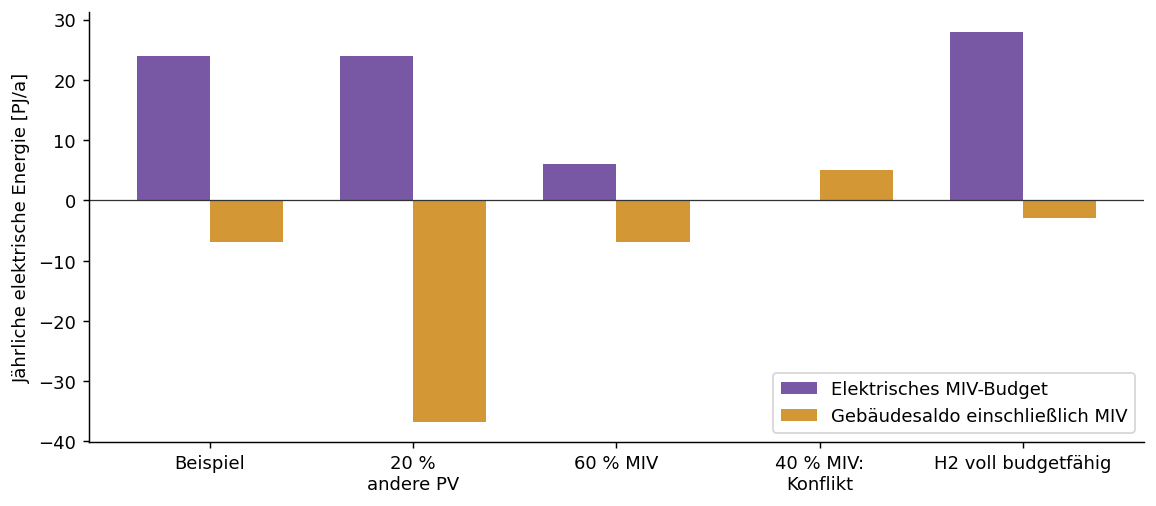

In [5]:
import copy
variants=[]
for label,f,m,h in [('Beispiel',0,.8,0),('20 % andere PV',.2,.8,0),('60 % MIV',0,.6,0),
                    ('40 % MIV: Konflikt',0,.4,0),('H2 voll budgetfähig',0,.8,1)]:
    p=copy.deepcopy(parameters)
    p.update(other_pv_share=f,miv_share=m,public_transport_share=1-m,other_transport_share=0)
    p['eligible_nonpv_share']['hydrogen_electricity']=h
    r=allocate(p)
    variants.append({'Variante':label,'Andere PV [%]':100*f,'MIV [%]':100*m,'H2-Anrechnung [%]':100*h,
                     'MIV-Budget [PJ_el/a]':r['miv_budget_pj'],'Gebäudesaldo [PJ_el/a]':r['building_target_pj'],
                     'Zentraler Rest [PJ_el/a]':r['central_after_miv_pj'],'Vorrang gedeckt':r['priority_covered']})
comparison=pd.DataFrame(variants)
display(comparison.round(3))
fig,ax=plt.subplots(figsize=(9,4))
x=np.arange(len(comparison))
ax.bar(x-.18,comparison['MIV-Budget [PJ_el/a]'],width=.36,color='#7857a5',label='Elektrisches MIV-Budget')
ax.bar(x+.18,comparison['Gebäudesaldo [PJ_el/a]'],width=.36,color='#d39736',label='Gebäudesaldo einschließlich MIV')
ax.axhline(0,color='#333',linewidth=.7)
ax.set_xticks(x,comparison.Variante.str.replace(': ',':\n').str.replace(' andere','\nandere'))
ax.set_ylabel('Jährliche elektrische Energie [PJ/a]');ax.legend(loc='best');fig.tight_layout()
fig.savefig(OUT/'allokation_varianten.png',dpi=180)
plt.show()


## 7. Primärenergie und nutzungsbezogene Gutschrift

Die sektorale Zuordnung bleibt in elektrischer Endenergie 2040. Für die spätere Bewertung mit heutigen Konversionsfaktoren gilt \(E_{PE,MIV}=M\,f_{PE,Strom}\). Das ist die Bewertung des zugeordneten Strombudgets, keine Prognose des PE-Faktors 2040. Eine vollständige physische PE-Quartiersbilanz benötigt zusätzlich die übrigen Energieträger und die zeitlichen Faktoren. Ein jährlicher Ersatzfaktor ist nur bei dokumentierter Kompatibilität mit dem Bewertungsverfahren zulässig; monatliche Gewichtungen können einen einzelnen Jahresfaktor unzureichend machen.

Hier liegt kein freigegebener heutiger Faktorensatz vor. PE-Budget und spezifische Gutschrift bleiben deshalb **offen**, nicht null. Auch Nutzungsanteile und Ziel-NGF sind nicht neu gesetzt. Die historische Gutschrift 2023 wird durch das elektrische Rechenbeispiel nicht ersetzt.


In [6]:
factor=parameters['pe_factor_electricity']
if factor is None:
    primary_energy_budget=None
else:
    assert np.isfinite(factor) and factor>=0
    assert parameters['pe_factor_year'] and parameters['pe_factor_source']
    primary_energy_budget=result['miv_budget_pj']*factor
display(pd.DataFrame([{'Elektrisches MIV-Budget [PJ/a]':result['miv_budget_pj'],
                      'PE-Budget [PJ_PE/a]':primary_energy_budget,
                      'Status':'Offen: belegter Faktorensatz und nutzungsbezogene Verteilung fehlen' if factor is None else 'Parametrierte Umrechnung'}]))


,Elektrisches MIV-Budget [PJ/a],PE-Budget [PJ_PE/a],Status
0,24.0,None,Offen: belegter Faktorensatz und nutzungsbezog...


## 8. Kontrollen, Ausgaben und nächste Entscheidungen

Geprüft werden Quellsummen, positive Zuordnungen, Verkehrssumme, PV-Erhaltung und der vollständige Bilanzrest. Grenzfälle prüfen 0/100 % andere PV sowie 0/100 % MIV. Kleine Quellenreste werden erhalten. Outputs enthalten Parameter, Quellen-Hashes, Resultate und die fünf Varianten. Die QMD-Ergebnistabelle wird aus diesen Rechnungen erzeugt; sie enthält keine separat eingegebenen Ergebniszahlen.

Für eine normative Festlegung fehlen insbesondere: begründete PV- und Verkehrsanteile, Herkunft/Anrechenbarkeit der Rückverstromung und der Sammelposition Geothermie/sonstige, Verwendung der anderen PV, Priorisierung der Systembedarfe und ein heutiger PE-Faktorensatz. Der Gebäudetypologie-Pool und eine neue Dichtekalibrierung sind ausdrücklich zurückgestellt.


In [7]:
for f,m,h in [(0,0,0),(1,1,0),(1,0,1),(0,1,1)]:
    p=copy.deepcopy(parameters);p.update(other_pv_share=f,miv_share=m,public_transport_share=1-m)
    p['eligible_nonpv_share']['hydrogen_electricity']=h
    r=allocate(p)
    assert np.isclose(r['building_pv_pj']+r['other_pv_pj'],g['pv'])
    assert np.isclose(r['allocation_residual_pj'],-2)
for bad in [-.01,1.01]:
    p=copy.deepcopy(parameters);p['other_pv_share']=bad
    try: allocate(p)
    except AssertionError: pass
    else: raise AssertionError('Ungültiger PV-Anteil akzeptiert')
payload={'parameters':parameters,'result':result,'pe_budget_pj':primary_energy_budget,'source_sha256':provenance}
(OUT/'allokation.json').write_text(json.dumps(payload,ensure_ascii=False,indent=2),encoding='utf-8')
result_table.to_csv(OUT/'referenzfall.csv',index=False)
comparison.to_csv(OUT/'varianten.csv',index=False)
shown=comparison.round(3).copy()
shown['Vorrang gedeckt']=shown['Vorrang gedeckt'].map({True:'ja',False:'nein'})
table='| '+' | '.join(shown.columns)+' |\n| '+' | '.join(['---']*len(shown.columns))+' |\n'
table+='\n'.join('| '+' | '.join(map(str,row))+' |' for row in shown.itertuples(index=False,name=None))
caption='\n\n: Eigene vorläufige Allokationsrechnung mit UBA Transition 2040; Verkehrs- und PV-Anteile sind Rechenannahmen. Ein negativer zentraler Rest kennzeichnet einen Allokationskonflikt. {#tbl-allokation-vorlaeufig}\n'
(ROOT/'Kapitel/_generated/allokation-ergebnisse.qmd').write_text(table+caption,encoding='utf-8')
print('Alle Bilanz- und Grenzfallkontrollen bestanden. Ausgaben:',OUT.relative_to(ROOT))


Alle Bilanz- und Grenzfallkontrollen bestanden. Ausgaben: Berechnungen\sektorenmodell\outputs\allokation
